# Mission 1: Understanding the Matrix

**Dataset**

| House | Area | Bedrooms | Age |
|---|---|---|---|
| H1 | 120 | 3 | 10 |
| H2 | 150 | 4 | 8 |
| H3 | 180 | 4 | 6 |
| H4 | 210 | 5 | 4 |

### Manual Work

**1. Represent the dataset as a matrix**

$$
X = \begin{bmatrix}
120 & 3 & 10 \\
150 & 4 & 8 \\
180 & 4 & 6 \\
210 & 5 & 4
\end{bmatrix}
$$

**2. Matrix shape:** 4 × 3

**3. Number of rows = 4**, **Number of columns = 3**

**4. Explanation:**
- **Each row** represents one house (one sample / observation): H1, H2, H3, H4.
- **Each column** represents one feature of the houses: Area, Bedrooms, Age

In [ ]:
import numpy as np


X = np.array([[120, 3, 10],
              [150, 4, 8],
              [180, 4, 6],
              [210, 5, 4]])

print(X,'\n')
print("Shape:", X.shape)

print("Number of rows:", X.shape[0])
print("Number of columns:", X.shape[1])

[[120   3  10]
 [150   4   8]
 [180   4   6]
 [210   5   4]] 

Shape: (4, 3)
Number of rows: 4
Number of columns: 3


### AI Insight
**What do rows and columns represent in Machine Learning?**
- **Rows = samples (observations / data points).**
- **Columns = features (variables).**
- So a dataset with shape (n, m) means **n samples and m features**. Our X has 4 samples and 3 features.

# Mission 2: Matrix Operations

Each operation is applied to the **original** matrix X.

### Manual Work

**1. Add 2 to every Age value** (third column):

Age: [10, 8, 6, 4] + 2 = **[12, 10, 8, 6]**

$$
\begin{bmatrix}
120 & 3 & 12 \\
150 & 4 & 10 \\
180 & 4 & 8 \\
210 & 5 & 6
\end{bmatrix}
$$

**2. Subtract 1 from every Age value:**

Age: [10, 8, 6, 4] − 1 = **[9, 7, 5, 3]**

$$
\begin{bmatrix}
120 & 3 & 9 \\
150 & 4 & 7 \\
180 & 4 & 5 \\
210 & 5 & 3
\end{bmatrix}
$$

**3. Multiply the Area column by 1.1:**

- 120 × 1.1 = 132
- 150 × 1.1 = 165
- 180 × 1.1 = 198
- 210 × 1.1 = 231

$$
\begin{bmatrix}
132 & 3 & 10 \\
165 & 4 & 8 \\
198 & 4 & 6 \\
231 & 5 & 4
\end{bmatrix}
$$

**4. Transpose** (rows become columns), shape changes from 4 × 3 to **3 × 4**:

$$
X^T = \begin{bmatrix}
120 & 150 & 180 & 210 \\
3 & 4 & 4 & 5 \\
10 & 8 & 6 & 4
\end{bmatrix}
$$

In [ ]:
#Add

X_add = X.copy()
X_add[:, 2] = X_add[:, 2] + 2

print("Age + 2:\n", X_add)

Age + 2:
 [[120   3  12]
 [150   4  10]
 [180   4   8]
 [210   5   6]]


In [ ]:
#Subtract

X_sub = X.copy()
X_sub[:, 2] = X_sub[:, 2] - 1

print("Age - 1:\n", X_sub)

Age - 1:
 [[120   3   9]
 [150   4   7]
 [180   4   5]
 [210   5   3]]


In [ ]:
#Multiply

X_area = X.astype(float)
X_area[:, 0] = X_area[:, 0] * 1.1

print("Area * 1.1:\n", X_area)

Area * 1.1:
 [[132.   3.  10.]
 [165.   4.   8.]
 [198.   4.   6.]
 [231.   5.   4.]]


In [ ]:
#Transpose

print("X Transpose:\n", X.T)
print("Shape before:", X.shape)
print("Shape after:", X.T.shape)

X Transpose:
 [[120 150 180 210]
 [  3   4   4   5]
 [ 10   8   6   4]]
Shape before: (4, 3)
Shape after: (3, 4)


In [ ]:
# verify

print("Age + 2 correct:", np.array_equal(X_add[:, 2], np.array([12, 10, 8, 6])))
print("Age - 1 correct:", np.array_equal(X_sub[:, 2], np.array([9, 7, 5, 3])))
print("Area * 1.1 correct:", np.allclose(X_area[:, 0], np.array([132, 165, 198, 231])))
print("Transpose correct:", np.array_equal(X.T, np.array([[120, 150, 180, 210],
                                                           [3, 4, 4, 5],
                                                           [10, 8, 6, 4]])))

Age + 2 correct: True
Age - 1 correct: True
Area * 1.1 correct: True
Transpose correct: True


### AI Insight
**Which operation changes values?**
Addition, subtraction and multiplying by 1.1. They change the numbers inside the matrix, but the shape stays 4 × 3.

**Which operation changes structure?**
The transpose. It keeps the same numbers but rearranges them: rows become columns and the shape changes from 4 × 3 to 3 × 4.

**Why is transpose useful?**
- It lets us match matrix dimensions so multiplication is possible (inner dimensions must be equal).
- It switches the view between "houses as rows" and "features as rows".
- It is used in many ML formulas, for example the covariance matrix (Xᵀ X) and the normal equation for linear regression: w = (Xᵀ X)⁻¹ Xᵀ y.

# Mission 3: AI Prediction

**Weights**

| Feature | Weight |
|---|---|
| Area | 2 |
| Bedrooms | 20 |
| Age | -5 |

### Manual Work

**1. Weight matrix** (column vector, one weight per feature):

$$
W = \begin{bmatrix} 2 \\ 20 \\ -5 \end{bmatrix}
$$

**2. Matrix multiplication:** X is (4 × 3) and W is (3 × 1). The inner dimensions match (3 = 3), so the result is **(4 × 1)**: one score per house. (The X that we defined at the beginning)

$$
\text{Score} = X \times W
$$

**3. Prediction score** for each house: Score = (Area × 2) + (Bedrooms × 20) + (Age × −5)

- **H1:** (120 × 2) + (3 × 20) + (10 × −5) = 240 + 60 − 50 = **250**
- **H2:** (150 × 2) + (4 × 20) + (8 × −5) = 300 + 80 − 40 = **340**
- **H3:** (180 × 2) + (4 × 20) + (6 × −5) = 360 + 80 − 30 = **410**
- **H4:** (210 × 2) + (5 × 20) + (4 × −5) = 420 + 100 − 20 = **500**

$$
\text{Score} = \begin{bmatrix} 250 \\ 340 \\ 410 \\ 500 \end{bmatrix}
$$

H4 has the highest score: it is the largest, has the most bedrooms and is the newest.

In [ ]:
#weight matrix

W = np.array([[2],
              [20],
              [-5]])

print(W)
print("Shape:", W.shape)

[[ 2]
 [20]
 [-5]]
Shape: (3, 1)


In [ ]:
#Multiplication

scores = X @ W

print("X @ W:\n", scores)
print("Shape:", scores.shape)

X @ W:
 [[250]
 [340]
 [410]
 [500]]
Shape: (4, 1)


In [ ]:
#Prediction score for each house

houses = ["H1", "H2", "H3", "H4"]

for house, score in zip(houses, scores):
    print(house, "score =", score[0])

H1 score = 250
H2 score = 340
H3 score = 410
H4 score = 500


In [ ]:
# verify

manual_scores = np.array([[250],
                          [340],
                          [410],
                          [500]])

print("Manual = NumPy:", np.array_equal(scores, manual_scores))

Manual = NumPy: True


### AI Insight
**Where is matrix multiplication used in AI?**
- **Linear models (linear regression):** predictions are computed as y = X W + b, exactly what we did here.
- **Neural networks:** every layer multiplies its inputs by a weight matrix, then applies an activation function.
- **Training:** computing errors and gradients to update the weights is done with matrix multiplication.
- **Speed:** multiplying the whole matrix at once gives predictions for all samples together, which is much faster than looping one by one (this is why GPUs are used in AI).

# Mission 4 — Detecting Redundant Features
The company added a new feature.

| House | Area | Bedrooms | Age | Rooms
|---|---|---|---| --- |
| H1 | 120 | 3 | 10 | 6 |
| H2 | 150 | 4 | 8 | 8 |
| H3 | 180 | 4 | 6 | 8 |
| H4 | 210 | 5 | 4 | 10 |

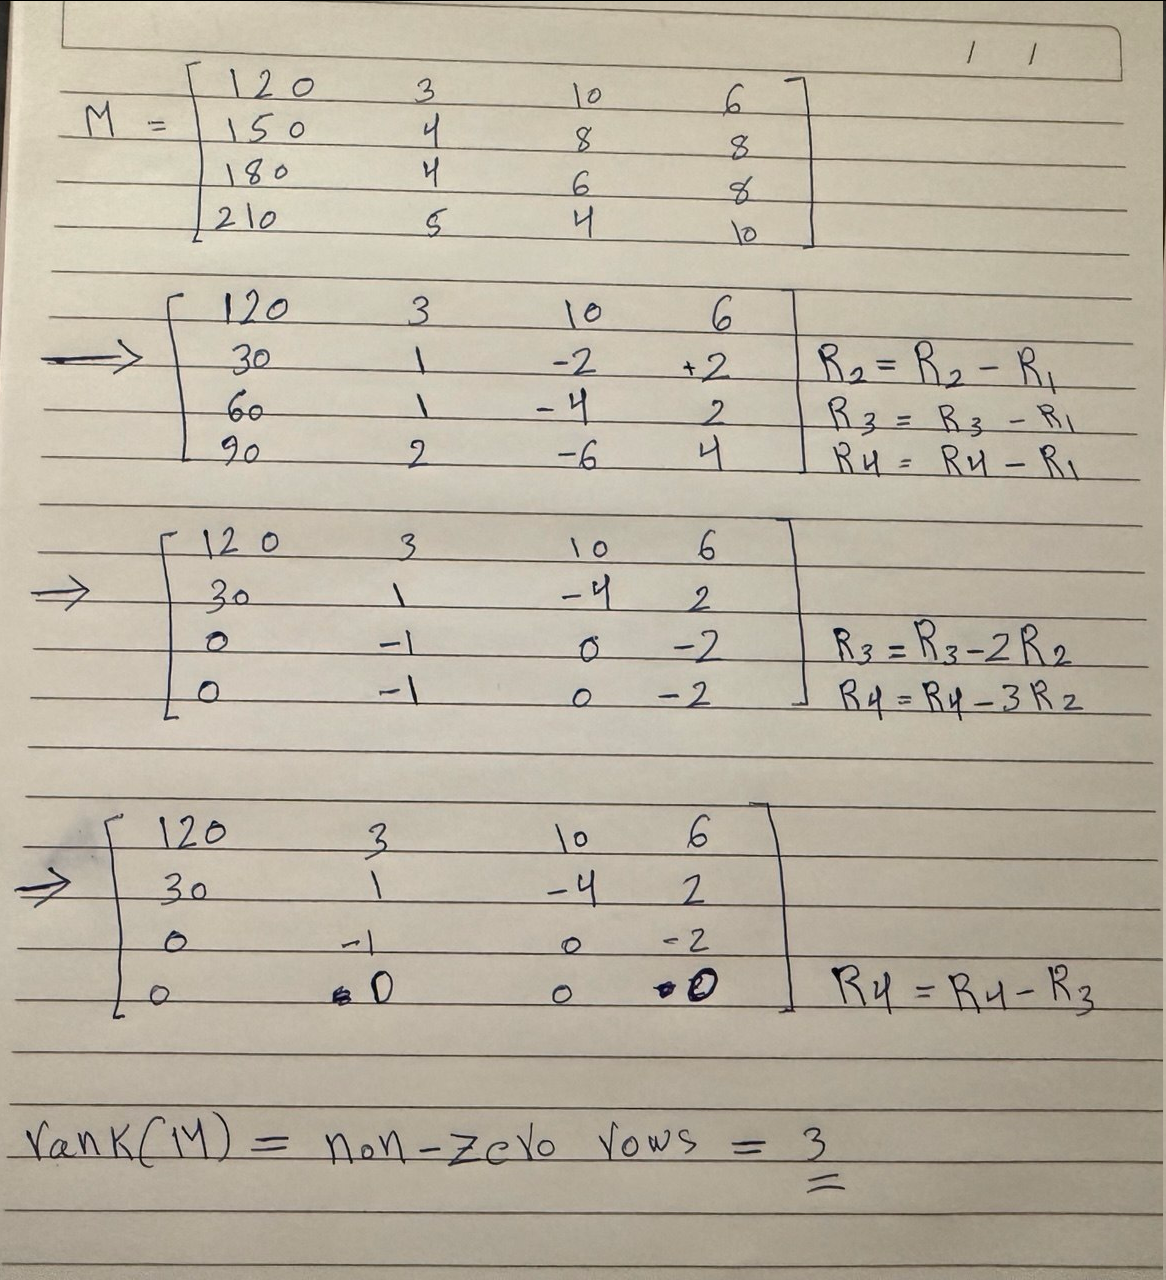

In [ ]:

X = np.array([[120, 3, 10 ,6],
              [150, 4, 8, 8],
              [180, 4, 6 , 8],
              [210, 5, 4 , 10]])

print ("rank = ",np.linalg.matrix_rank(X)) # = 3 , rank < Number of rows , means that the columns are linearly dependent
                                           #  c4 = c2 * 2 ->  there is redundant information in the matrix one column can be written as a combination of the others.

rank =  3


# AI Insight
Why are redundant features harmful?

they provide no new information but significantly increase the computational burden and degrade model performance.

# Mission 5 — Determinant, Identity Matrix & Inverse
Matrix A

| 2 1 |

| 4 2 |

Matrix B

| 2 1 |

| 3 2 |

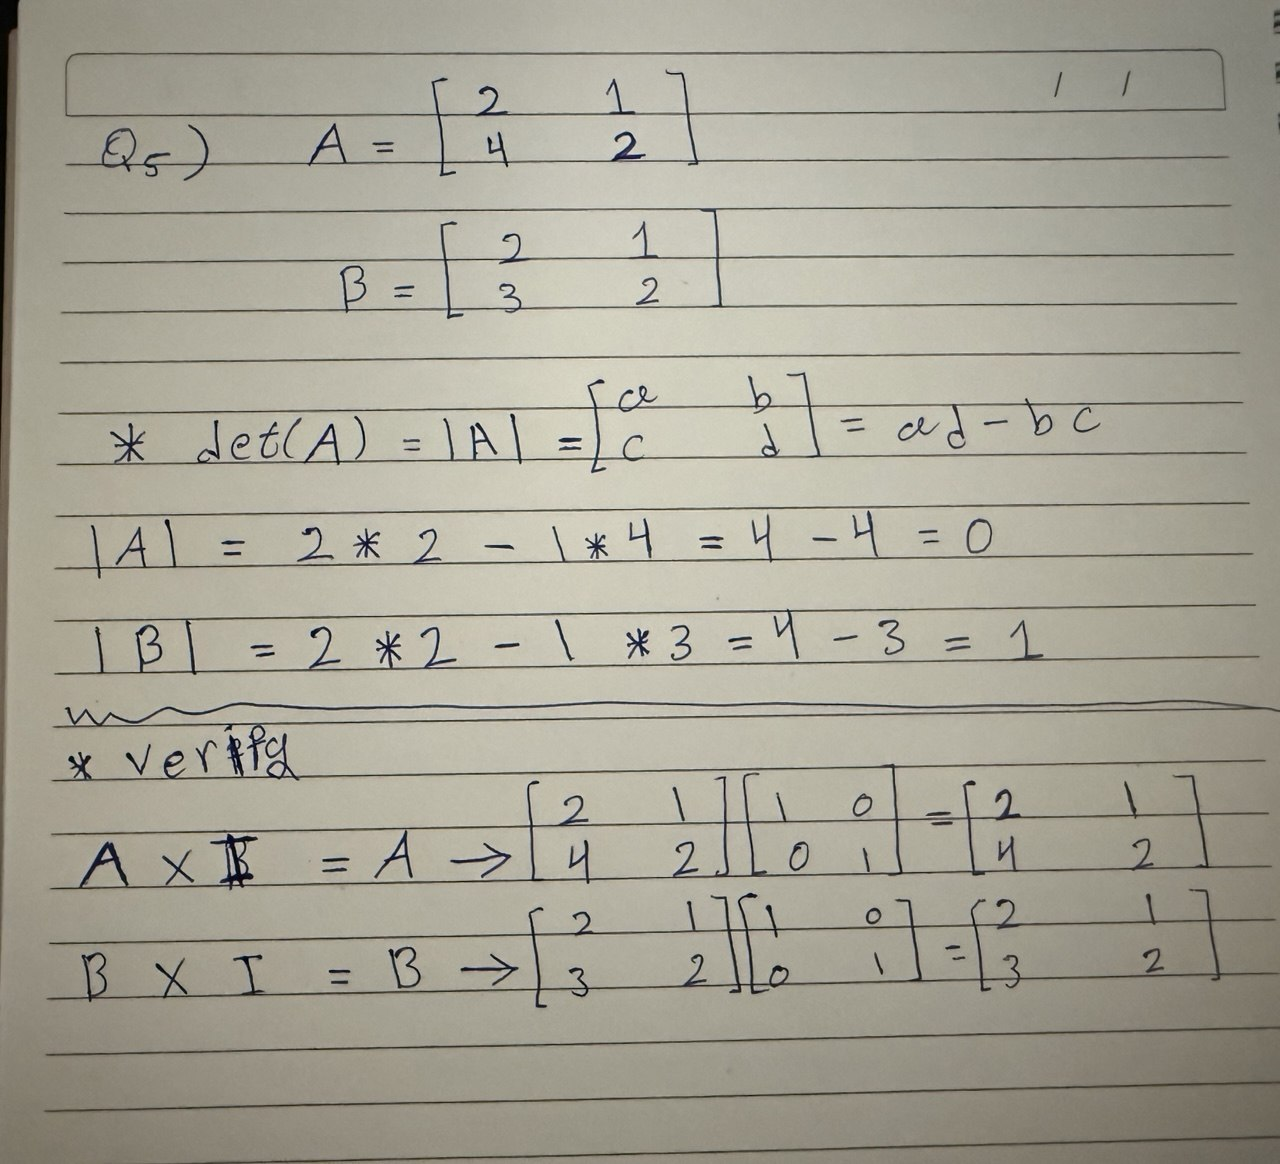

In [ ]:


A = np.array([[2,1],[4,2]])
B = np.array([[2,1],[3,2]])
identity = np.array([[1,0],[0,1]])

print("determinant of Matrix A = ",np.linalg.det(A)) # = 0 which means this matrix is invertible.
print("determinant of Matrix B = ",np.linalg.det(B))

print("A × I = A -> \n" ,A @ identity)
print("B × I = B -> \n" ,B @ identity)

print("B inverse : \n",np.linalg.inv(B))

determinant of Matrix A =  0.0
determinant of Matrix B =  0.9999999999999998
A × I = A -> 
 [[2 1]
 [4 2]]
B × I = B -> 
 [[2 1]
 [3 2]]
B inverse : 
 [[ 2. -1.]
 [-3.  2.]]


# AI Insight
- What does determinant = 0 mean? The matrix is classified as singular and cannot be inverted
- Why can't a singular matrix be inverted? Division by zero
- Why is the inverse important in Machine Learning? Linear regression: the Normal Equation $\theta = (X^TX)^{-1}X^Ty$ requires $X^TX$ to be invertible.

# Mission 6 — Solving Linear Systems
Given

2x + y = 7

x − y = 2

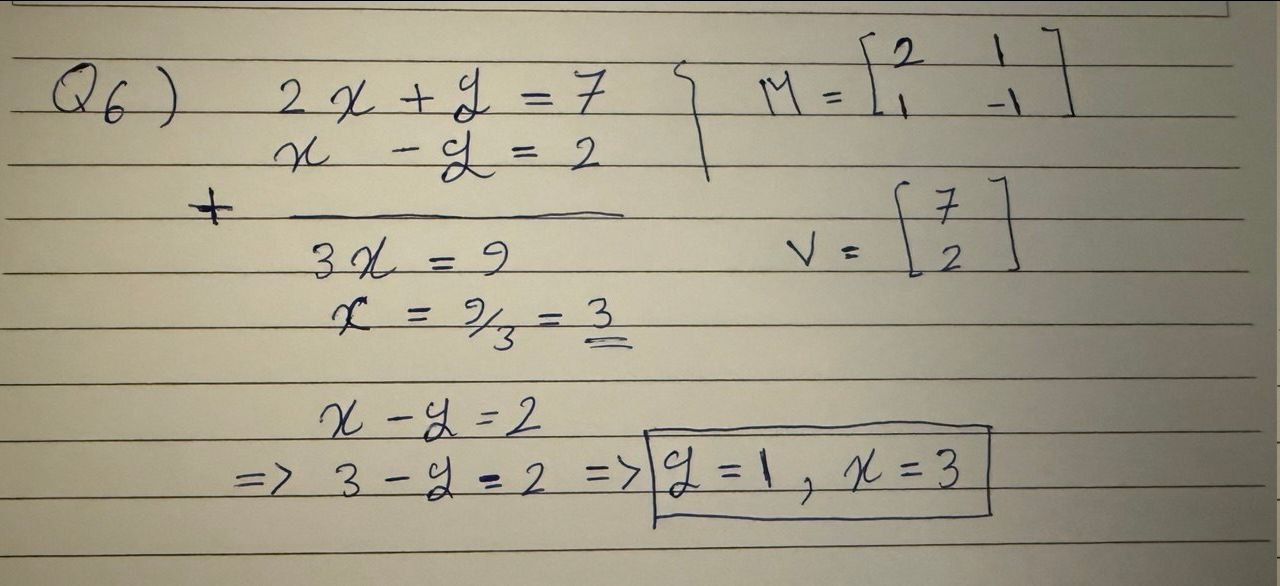

In [ ]:
M = np.array([[2,1],[1,-1]])
V = np.array([7,2])

print("x,y = ",np.linalg.solve(M,V))

x,y =  [3. 1.]


# AI Insight
Why are systems of equations important in Machine Learning?

Because training a model means finding the weights, and each data point gives you an equation like weight₁·feature₁ + weight₂·feature₂ + … = target. Put all your data together and you get a system of equations, $Xw = y$. Solving it, or approximately solving it when the data is noisy, is how the model learns.